In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import datasets, transforms
import numpy as np
import os
import sys
from pathlib import Path
import itertools
import torchvision.transforms.functional as TF


# Parameters
input_frames = 10  # Number of frames per video
resize_shape = (28, 28)  # Desired resize shape (height, width)
batch_size = 1000
num_classes = 10
num_epochs = 20
learning_rate = 0.001
padding_size = 1

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

PWD = Path(os.path.abspath('')).parent.resolve()
MODELS_PATH = Path(os.path.abspath('')).parent.resolve() / "models/"

MNIST_DATASET_PATH = Path('/vol/bitbucket/svadakku/data/mnist/')

In [2]:

# Dataset to convert MNIST into sequence of frames
class MNISTVideoDataset(Dataset):
    def __init__(self, root, train=True, transform=None, frames=input_frames, resize_shape=(10, 10)):
        self.mnist = datasets.MNIST(root=root, train=train, download=True, transform=transform)
        self.frames = frames  # Number of frames per video
        self.resize_shape = resize_shape  # Target image resolution
        self.rotation = itertools.cycle([0, 5, 10, 15, 20, 25, -25, -20, -15, -10])  # Rotate images for variety
        self.translate = itertools.cycle([(0,0), (0,1), (1,2), (2,3), (3,4), (4,5), (-4,-5), (-3,-4), (-3,-2), (-2,-1)])  # Translate images for variety
        self.transform = transforms.Compose([
            transforms.Resize(resize_shape),  # Resize to specified resolution
            transforms.ToTensor(),
            #transforms.Pad(padding=padding_size),

            transforms.Lambda(lambda img: TF.affine( 
                img, 
                angle=next(self.rotation),  # Rotate images
                translate=next(self.translate), # Translate images
                scale=1.0, 
                shear=0
            )), 
            transforms.Normalize((0.5,), (0.5,))
        ])

    def __len__(self):
        # Dataset length is based on MNIST size divided by frames to form videos
        return len(self.mnist) // self.frames

    def __getitem__(self, idx):
        # Collect `frames` consecutive MNIST images to form a video
        start_idx = idx * self.frames
        video_frames = []
        label = self.mnist[start_idx][1]  # Label is taken from the first frame in the sequence

        for i in range(self.frames):
            img, _ = self.mnist[start_idx]  # Ignore the label for other frames
            img = self.transform(img)  # Resize and transform each image
            video_frames.append(img.squeeze(0).numpy())  # Remove channel dim for stacking

        # Stack frames to shape (1, frames, H, W) for 3D CNN
        video_tensor = torch.tensor(np.stack(video_frames, axis=0), dtype=torch.float32).unsqueeze(0)
        return video_tensor, label

# Load training and validation datasets
train_dataset = MNISTVideoDataset(root=MNIST_DATASET_PATH, train=True, frames=input_frames, resize_shape=resize_shape)
val_dataset = MNISTVideoDataset(root=MNIST_DATASET_PATH, train=False, frames=input_frames, resize_shape=resize_shape)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

# Model definition (same as before)
class Simple3DCNN(nn.Module):
    def __init__(self):
        super(Simple3DCNN, self).__init__()
        self.conv1 = nn.Conv3d(in_channels=1, out_channels=2, kernel_size=2, stride=1, padding=0)
        self.conv2 = nn.Conv3d(in_channels=2, out_channels=4, kernel_size=2, stride=1, padding=1)
        self.conv3 = nn.Conv3d(in_channels=4, out_channels=8, kernel_size=2, stride=1, padding=1)
        
        # self.relu = nn.ReLU(inplace=True)
        
        # Calculate flattened size after conv layers by passing a dummy tensor
        dummy_input = torch.rand(1, 1, input_frames, *resize_shape)  # Use resized input shape
        dummy_output = self._forward_conv_layers(dummy_input)
        flattened_size = dummy_output.view(1, -1).size(1)
        print(flattened_size)
        # Fully connected layers
        #flattened_size = 32
        self.fc1 = nn.Linear(flattened_size, 128)
        self.fc2 = nn.Linear(128, num_classes)
        

    def _forward_conv_layers(self, x):
        x = nn.ReLU()(self.conv1(x))
        #x = F.max_pool3d(x, kernel_size=2, stride=2)
        x = nn.ReLU()(self.conv2(x))
        #x = F.max_pool3d(x, kernel_size=2, stride=2)
        x = nn.ReLU()(self.conv3(x))
        #x = F.max_pool3d(x, kernel_size=2, stride=2)
        return x

    def forward(self, x):
        x = self._forward_conv_layers(x)
        x = x.view(x.size(0), -1)  # Flatten
        #print("Flattend shape: ", x.shape)
        x = nn.ReLU()(self.fc1(x))
        x = self.fc2(x)
        return x



tensor(6)


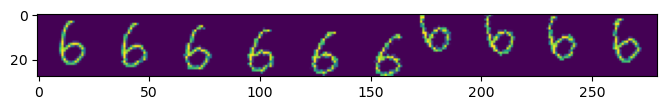

In [3]:
import matplotlib.pyplot as plt

first_batch_inputs = next(iter(train_loader))
input_tensor = first_batch_inputs[0]
video = input_tensor[0].squeeze(0)
plt.figure(figsize=(8,8), dpi=100)
plt.imshow(np.hstack(video.cpu().detach().numpy()))
print(first_batch_inputs[1][0])



In [ ]:
# Instantiate model, loss, and optimizer
model = Simple3DCNN()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

# Training function (same as before)
def train(model, train_loader, criterion, optimizer, epoch):
    model.train()
    running_loss = 0.0
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    avg_loss = running_loss / len(train_loader)
    print(f"Epoch {epoch+1} Training Loss: {avg_loss:.4f}")

# Validation function (same as before)
def validate(model, val_loader, criterion):
    model.eval()
    val_loss = 0.0
    correct = 0
    with torch.no_grad():
        for data, target in val_loader:
            output = model(data)
            val_loss += criterion(output, target).item()
            pred = output.argmax(dim=1, keepdim=True)
            correct += pred.eq(target.view_as(pred)).sum().item()
    
    avg_loss = val_loss / len(val_loader)
    accuracy = correct / len(val_loader.dataset)
    print(f"Validation Loss: {avg_loss:.4f}, Accuracy: {accuracy:.4f}")

# Training loop (same as before)
for epoch in range(num_epochs):
    train(model, train_loader, criterion, optimizer, epoch)
    validate(model, val_loader, criterion)


74008
Epoch 1 Training Loss: 2.7916
Validation Loss: 2.6184, Accuracy: 0.1590
Epoch 2 Training Loss: 2.4288
Validation Loss: 2.2218, Accuracy: 0.1620
Epoch 3 Training Loss: 2.1154
Validation Loss: 2.0032, Accuracy: 0.4870
Epoch 4 Training Loss: 1.8760
Validation Loss: 1.7104, Accuracy: 0.6470
Epoch 5 Training Loss: 1.5415
Validation Loss: 1.3280, Accuracy: 0.7200
Epoch 6 Training Loss: 1.1399
Validation Loss: 0.9407, Accuracy: 0.7620
Epoch 7 Training Loss: 0.8104
Validation Loss: 0.6887, Accuracy: 0.7970
Epoch 8 Training Loss: 0.6126
Validation Loss: 0.5653, Accuracy: 0.8190
Epoch 9 Training Loss: 0.4929
Validation Loss: 0.4714, Accuracy: 0.8610
Epoch 10 Training Loss: 0.4059
Validation Loss: 0.4389, Accuracy: 0.8570
Epoch 11 Training Loss: 0.3547
Validation Loss: 0.4054, Accuracy: 0.8780
Epoch 12 Training Loss: 0.3127
Validation Loss: 0.3778, Accuracy: 0.8930
Epoch 13 Training Loss: 0.2814
Validation Loss: 0.3506, Accuracy: 0.8910
Epoch 14 Training Loss: 0.2562
Validation Loss: 0.3534

In [5]:
import os

# Directory to save the model
model_dir = MODELS_PATH
os.makedirs(model_dir, exist_ok=True)
model_path = os.path.join(model_dir, "simple_3d_cnn.pth")

# Save the trained model
torch.save(model.state_dict(), model_path)
print(f"Model saved to {model_path}")


Model saved to /data/sv/temporal-nn-verification/mnist_toy_example/models/simple_3d_cnn.pth
